# Look back at a cyclone with ERA5 🌀
### Copernicus Climate Change Service · ERA5 reanalysis · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/unicef/cyclone_era5.ipynb)

**ERA5** is ECMWF's reconstruction of the weather everywhere on Earth, every hour since 1940. It is how you look back
at an event after it has happened: how much rain fell, where, and how strong the wind was.

This notebook maps **Cyclone Gezani** coming ashore near Toamasina, Madagascar, on 10 February 2026. UNICEF acted
before landfall with CERF early-action funding. Change the date and box to look at any storm since 1940.

*In Google Colab? Press **Runtime → Run all**.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open too, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the dataset page and accept its licence (Download tab, bottom of the page). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.
   It is kept only for this Colab session and is not saved in the notebook.

In [2]:
import os
from getpass import getpass
if not os.path.exists(os.path.expanduser("~/.cdsapirc")):
    key = getpass("Copernicus API key: ")
    for url, rc in (("https://cds.climate.copernicus.eu/api", "~/.cdsapirc"),
                    ("https://ads.atmosphere.copernicus.eu/api", "~/.adsapirc")):
        with open(os.path.expanduser(rc), "w") as f:
            f.write(f"url: {url}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the event

In [4]:
EVENT = "Cyclone Gezani"
DAY   = "2026-02-10"
HOURS = ["12:00", "13:00", "14:00", "15:00", "16:00", "17:00"]   # UTC; rain is added up over these hours
AREA  = [-10, 42, -27, 56]                                         # north, west, south, east
CITIES = [("Toamasina", -18.149, 49.402), ("Antananarivo", -18.879, 47.508), ("Mahajanga", -15.717, 46.317)]

## 2 · Get ERA5 from the Climate Data Store

In [5]:
y, m, d = DAY.split("-")
era5 = ekd.from_source("cds", "reanalysis-era5-single-levels", {
    "product_type": "reanalysis", "variable": ["total_precipitation", "10m_u_component_of_wind", "10m_v_component_of_wind"],
    "year": y, "month": m, "day": d, "time": HOURS, "area": AREA, "data_format": "grib"}).to_fieldlist()
ds = era5.to_xarray(time_dims=["valid_time"])                     # one time axis
rain = ds["tp"].sum("valid_time") * 1000                            # metres -> mm over the period
u, v = ds["10u"].isel(valid_time=-1), ds["10v"].isel(valid_time=-1) # wind at the last hour
print(f"Most rain in {len(HOURS)} hours: {float(rain.max()):.0f} mm; strongest 10 m wind: {float(np.hypot(u, v).max()) * 3.6:.0f} km/h")

Most rain in 6 hours: 125 mm; strongest 10 m wind: 74 km/h


## 3 · Map rain and wind

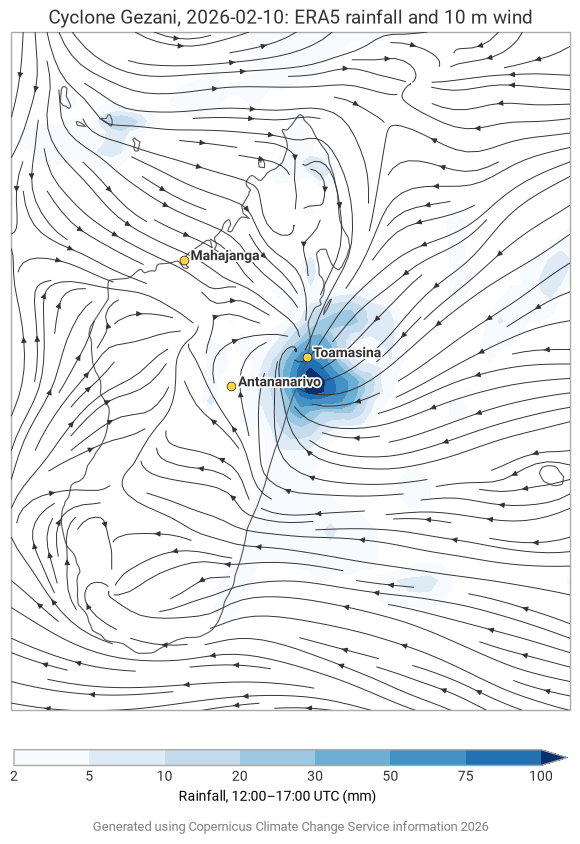

In [6]:
style = ekp.styles.Style(levels=[2, 5, 10, 20, 30, 50, 75, 100], colors="Blues", extend="max")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]])
chart.contourf(rain, style=style)
chart.ax.streamplot(u.longitude.values, u.latitude.values, u.values, v.values, color="#333333", density=1.6,
                    linewidth=0.7, arrowsize=0.8, transform=ccrs.PlateCarree(), zorder=5)
chart.coastlines(linewidth=0.8); chart.borders(linewidth=0.6)
for name, la, lo in CITIES:
    chart.scatter(x=[lo], y=[la], s=40, color="#ffd23f", edgecolors="#1a1a1a", zorder=10)
    chart.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                  path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
chart.legend(label=f"Rainfall, {HOURS[0]}–{HOURS[-1]} UTC (mm)")
chart.title(f"{EVENT}, {DAY}: ERA5 rainfall and 10 m wind", fontsize=14)
chart.attribution("Generated using Copernicus Climate Change Service information 2026")
chart.save("cyclone_era5.png")
chart.show()

## 4 · Your turn 🌍

- **Super Typhoon Fung-wong (Uwan), Philippines:** `DAY = "2025-11-09"`, `AREA = [20, 118, 10, 130]`.
- **Hurricane Melissa, Jamaica:** `DAY = "2025-10-28"`, `AREA = [22, -82, 14, -72]`.
- ERA5 runs at about 31 km, so it smooths the very core of a cyclone: peak winds come out lower than observed, but the
  rain and the storm's footprint are well captured. For the land at 9 km, try `reanalysis-era5-land`.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0 for these datasets). Credit:
*Generated using Copernicus Climate Change Service / Atmosphere Monitoring Service information [year].*
ECMWF runs both services for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)